# Proyek Analisis Data: E-Commerce Public Dataset (Olist)

- **Nama:** (Syahidah Azzahro)
- **Email:** (zahro39@gmail.com)
- **ID Dicoding:** (syahidahazzahro)

## Daftar Isi
1. Menentukan Pertanyaan Bisnis
2. Import Library
3. Data Wrangling (Gathering, Assessing, Cleaning)
4. Exploratory Data Analysis (EDA), termasuk analisis lanjutan RFM dan binning
5. Visualization & Explanatory Analysis, termasuk analisis geospatial
6. Conclusion & Recommendation

## 1. Menentukan Pertanyaan Bisnis

Dataset ini berisi transaksi marketplace Olist di Brasil. Seluruh pertanyaan dibatasi pada pesanan berstatus **delivered** yang dibeli pada periode **Januari 2017 sampai Agustus 2018**. Bulan di luar periode ini hanya memuat sedikit transaksi sehingga tidak representatif. *Revenue* di seluruh analisis berarti jumlah harga barang (`price`), tidak termasuk ongkos kirim.

**Pertanyaan 1.** Kategori produk apa saja yang masuk 10 besar berdasarkan total revenue (R$) dan berapa persen kontribusinya terhadap total revenue pada periode Januari 2017 sampai Agustus 2018, **sebagai dasar menentukan prioritas stok, anggaran promosi, dan rekrutmen seller**?

**Pertanyaan 2.** Bagaimana sebaran jumlah pelanggan dan total revenue pada setiap segmen RFM (Champions, Loyal, New High Value, Promising, At Risk, Lost) pada periode Januari 2017 sampai Agustus 2018, dan segmen mana yang menyumbang revenue terbesar, **sebagai dasar menyusun strategi retensi dan win-back untuk setiap segmen**?

**Pertanyaan 3.** Di state mana pelanggan dan revenue paling terkonsentrasi, dan berapa rata-rata waktu pengiriman (hari) serta rata-rata review score di setiap state pada periode Januari 2017 sampai Agustus 2018, **sebagai dasar menentukan wilayah prioritas perbaikan logistik**?

### Pemeriksaan dengan metode SMART

| Unsur | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| **Specific** | Fokus pada kategori produk dan kontribusi revenue 10 besar | Fokus pada segmentasi RFM pelanggan | Fokus pada distribusi per state: pelanggan, revenue, waktu kirim, review |
| **Measurable** | Total revenue (R$) dan persentase kontribusi | Jumlah pelanggan dan total revenue per segmen | Jumlah pelanggan, revenue, rata-rata hari pengiriman, rata-rata review score |
| **Action-oriented** | Dasar prioritas stok, promosi, dan rekrutmen seller | Dasar strategi retensi dan win-back per segmen | Dasar menentukan wilayah prioritas perbaikan logistik |
| **Relevant** | Revenue adalah tujuan utama marketplace | Retensi pelanggan menentukan pertumbuhan jangka panjang | Pengiriman lambat menurunkan kepuasan pelanggan |
| **Time-bound** | Jan 2017 sampai Agu 2018 | Jan 2017 sampai Agu 2018 | Jan 2017 sampai Agu 2018 |

Setiap pertanyaan dijawab pada tahap berikut:

| Pertanyaan | EDA | Visualisasi | Kesimpulan dan rekomendasi |
|---|---|---|---|
| 1 | Bagian 4.2 | Bagian 5.1 | Kesimpulan Pertanyaan 1, rekomendasi 1 |
| 2 | Bagian 4.3 | Bagian 5.2 | Kesimpulan Pertanyaan 2, rekomendasi 2 |
| 3 | Bagian 4.4 | Bagian 5.3 sampai 5.5 | Kesimpulan Pertanyaan 3, rekomendasi 3 |

## 2. Import Library

In [24]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)

# Cari folder yang berisi file CSV dataset (lokal, Colab, atau Google Drive)
from pathlib import Path

CANDIDATES = ["data", ".", "../data", "dataset", "/content/data", "/content",
              "/content/drive/MyDrive/data", "/content/drive/MyDrive"]
DATA_DIR = next((p for p in CANDIDATES if Path(p, "orders_dataset.csv").exists()), None)

if DATA_DIR is None:
    raise FileNotFoundError(
        "File dataset tidak ditemukan. Letakkan 9 file CSV (orders_dataset.csv, customers_dataset.csv, dst.) "
        f"di folder 'data' sejajar dengan notebook ini.\nFolder kerja saat ini: {os.getcwd()}\n"
        "Di Google Colab: unggah file CSV ke folder /content/data atau mount Google Drive."
    )
print("Folder data :", DATA_DIR)
print("Folder kerja:", os.getcwd())

Folder data : .
Folder kerja: /content


## 3. Data Wrangling

### 3.1 Gathering Data

Memuat 9 file CSV ke dalam DataFrame. Tabel `orders` menjadi pusat, dan tabel lain dihubungkan lewat `order_id`, `customer_id`, `product_id`, atau kode pos.

In [25]:
customers_df = pd.read_csv(f"{DATA_DIR}/customers_dataset.csv")
geolocation_df = pd.read_csv(f"{DATA_DIR}/geolocation_dataset.csv")
order_items_df = pd.read_csv(f"{DATA_DIR}/order_items_dataset.csv")
order_payments_df = pd.read_csv(f"{DATA_DIR}/order_payments_dataset.csv")
order_reviews_df = pd.read_csv(f"{DATA_DIR}/order_reviews_dataset.csv")
orders_df = pd.read_csv(f"{DATA_DIR}/orders_dataset.csv")
category_df = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")
products_df = pd.read_csv(f"{DATA_DIR}/products_dataset.csv")
sellers_df = pd.read_csv(f"{DATA_DIR}/sellers_dataset.csv")

tables = {
    "customers": customers_df, "geolocation": geolocation_df,
    "order_items": order_items_df, "order_payments": order_payments_df,
    "order_reviews": order_reviews_df, "orders": orders_df,
    "category": category_df, "products": products_df, "sellers": sellers_df,
}
for name, df in tables.items():
    print(f"{name:<15} {df.shape[0]:>10,} baris x {df.shape[1]} kolom")

customers           99,441 baris x 5 kolom
geolocation      1,000,163 baris x 5 kolom
order_items        112,650 baris x 7 kolom
order_payments     103,886 baris x 5 kolom
order_reviews       99,224 baris x 7 kolom
orders              99,441 baris x 8 kolom
category                71 baris x 2 kolom
products            32,951 baris x 9 kolom
sellers              3,095 baris x 4 kolom


In [26]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight (Gathering):** seluruh tabel berhasil dimuat. Tabel `geolocation` paling besar (sekitar 1 juta baris) karena satu kode pos dapat memiliki banyak titik koordinat. Tabel `orders` memuat 99.441 pesanan, dan kolom tanggalnya masih terbaca sebagai teks.

### 3.2 Assessing Data

Pada tahap ini saya memeriksa missing value, duplikat, kesesuaian tipe data, nilai tidak valid atau tidak akurat, nilai tidak konsisten, dan outlier.

In [27]:
# 1) Missing value dan duplikat di setiap tabel
for name, df in tables.items():
    miss = df.isnull().sum()
    miss = miss[miss > 0]
    print(f"[{name}] baris duplikat: {df.duplicated().sum():,}")
    if len(miss):
        print(miss.to_string())
    print()

[customers] baris duplikat: 0

[geolocation] baris duplikat: 261,831

[order_items] baris duplikat: 0

[order_payments] baris duplikat: 0

[order_reviews] baris duplikat: 0
review_comment_title      87656
review_comment_message    58247

[orders] baris duplikat: 0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

[category] baris duplikat: 0

[products] baris duplikat: 0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2

[sellers] baris duplikat: 0



In [28]:
# 2) Tabel orders: tipe data, status, dan anomali tanggal
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
print("Tipe data kolom tanggal (asli):", orders_df[date_cols].dtypes.astype(str).unique())

chk = orders_df.copy()
for c in date_cols:
    chk[c] = pd.to_datetime(chk[c])

print("\nDistribusi status pesanan:")
print(chk["order_status"].value_counts().to_string())
print("\nRentang tanggal pembelian:", chk["order_purchase_timestamp"].min(), "sampai", chk["order_purchase_timestamp"].max())

delivered = chk[chk["order_status"] == "delivered"]
print("\nStatus 'delivered' tetapi tanggal diterima pelanggan kosong :", delivered["order_delivered_customer_date"].isnull().sum())
print("Status 'delivered' tetapi tanggal approval kosong            :", delivered["order_approved_at"].isnull().sum())
anom = delivered["order_delivered_carrier_date"].notna() & (delivered["order_delivered_customer_date"] < delivered["order_delivered_carrier_date"])
print("Tiba di pelanggan lebih awal dari diserahkan ke kurir        :", anom.sum())

print("\nPesanan per bulan (awal dan akhir periode):")
monthly = chk.groupby(chk["order_purchase_timestamp"].dt.to_period("M")).size()
print(monthly.head(5).to_string())
print("...")
print(monthly.tail(4).to_string())

Tipe data kolom tanggal (asli): ['object']

Distribusi status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Rentang tanggal pembelian: 2016-09-04 21:15:19 sampai 2018-10-17 17:30:18

Status 'delivered' tetapi tanggal diterima pelanggan kosong : 8
Status 'delivered' tetapi tanggal approval kosong            : 14
Tiba di pelanggan lebih awal dari diserahkan ke kurir        : 23

Pesanan per bulan (awal dan akhir periode):
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
Freq: M
...
order_purchase_timestamp
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


In [29]:
# 3) Produk dan kategori
print("Produk tanpa kategori:", products_df["product_category_name"].isnull().sum())
missing_trans = set(products_df["product_category_name"].dropna()) - set(category_df["product_category_name"])
print("Kategori yang tidak ada di tabel terjemahan:", missing_trans)

# 4) Review: satu pesanan dapat memiliki lebih dari satu review
print("\nOrder_id ganda pada tabel review:", order_reviews_df["order_id"].duplicated().sum())

# 5) Geolocation: duplikat dan koordinat di luar Brasil
geo_dup = geolocation_df.duplicated().sum()
outside = ~(geolocation_df["geolocation_lat"].between(-33.75, 5.28) & geolocation_df["geolocation_lng"].between(-73.99, -34.79))
print(f"\nGeolocation: {geo_dup:,} baris duplikat ({geo_dup / len(geolocation_df):.1%}), {outside.sum()} titik di luar wilayah Brasil")
print("Contoh nama kota tidak konsisten:", geolocation_df.loc[geolocation_df["geolocation_city"].str.contains("sa£o|sãopaulo", regex=True), "geolocation_city"].unique()[:4])

# 6) Outlier harga barang (aturan IQR)
q1, q3 = order_items_df["price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
n_out = (order_items_df["price"] > upper).sum()
print(f"\nOutlier harga (> {upper:,.2f}): {n_out:,} item ({n_out / len(order_items_df):.1%}); harga maksimum {order_items_df['price'].max():,.2f}")

Produk tanpa kategori: 610
Kategori yang tidak ada di tabel terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}

Order_id ganda pada tabel review: 551

Geolocation: 261,831 baris duplikat (26.2%), 42 titik di luar wilayah Brasil
Contoh nama kota tidak konsisten: ['sãopaulo' 'sa£o paulo']

Outlier harga (> 277.40): 8,427 item (7.5%); harga maksimum 6,735.00


**Ringkasan hasil assessing dan solusi (untuk tahap cleaning):**

| No | Jenis masalah | Temuan | Solusi |
|---|---|---|---|
| 1 | Inconsistent value (tipe data) | Seluruh kolom tanggal pada `orders` bertipe teks | Konversi dengan `pd.to_datetime` |
| 2 | Invalid value | Pesanan berstatus `canceled`, `unavailable`, `shipped`, dan lain-lain tidak menghasilkan revenue final | Hanya memakai pesanan `delivered` |
| 3 | Missing value | Status `delivered` tetapi tanggal diterima pelanggan kosong; kategori produk kosong (610 produk) | Buang pesanan tanpa tanggal terima; isi kategori kosong dengan `unknown` |
| 4 | Inaccurate value | Sebagian pesanan tercatat tiba sebelum diserahkan ke kurir | Buang pesanan dengan urutan tanggal yang tidak logis |
| 5 | Inconsistent value (kategori) | Dua kategori tidak ada di tabel terjemahan | Tambahkan terjemahan manual |
| 6 | Duplicate data | Review ganda per pesanan (551) dan 261 ribu baris duplikat di `geolocation` | Rata-ratakan skor review per pesanan; `drop_duplicates` pada geolocation |
| 7 | Outlier | Koordinat di luar Brasil pada `geolocation`; harga barang sangat tinggi | Koordinat di luar Brasil dibuang. Harga tinggi **dipertahankan** karena produk bernilai besar memang valid |
| 8 | Data di luar periode | Transaksi 2016 dan setelah Agustus 2018 sangat sedikit | Batasi analisis pada Jan 2017 sampai Agu 2018 |

### 3.3 Cleaning Data

In [30]:
# --- Orders: tipe data, status, periode, dan anomali tanggal ---
orders_clean = orders_df.copy()
for c in date_cols:
    orders_clean[c] = pd.to_datetime(orders_clean[c])
n0 = len(orders_clean)

orders_clean = orders_clean[orders_clean["order_status"] == "delivered"]
n1 = len(orders_clean)

orders_clean = orders_clean.dropna(subset=["order_delivered_customer_date"])
n2 = len(orders_clean)

in_period = (orders_clean["order_purchase_timestamp"] >= "2017-01-01") & (orders_clean["order_purchase_timestamp"] < "2018-09-01")
orders_clean = orders_clean[in_period]
n3 = len(orders_clean)

bad_order = orders_clean["order_delivered_carrier_date"].notna() & (orders_clean["order_delivered_customer_date"] < orders_clean["order_delivered_carrier_date"])
orders_clean = orders_clean[~bad_order]
n4 = len(orders_clean)

print(f"Pesanan awal                          : {n0:,}")
print(f"Setelah filter status 'delivered'     : {n1:,}")
print(f"Setelah buang tanggal terima kosong   : {n2:,}")
print(f"Setelah filter periode 2017-01..2018-08: {n3:,}")
print(f"Setelah buang urutan tanggal tak logis: {n4:,}")

Pesanan awal                          : 99,441
Setelah filter status 'delivered'     : 96,478
Setelah buang tanggal terima kosong   : 96,470
Setelah filter periode 2017-01..2018-08: 96,203
Setelah buang urutan tanggal tak logis: 96,184


In [31]:
# --- Produk: terjemahan kategori dan nilai kosong ---
translation = category_df.set_index("product_category_name")["product_category_name_english"].to_dict()
translation.update({
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_and_food_preparers",
})
products_clean = products_df[["product_id", "product_category_name"]].copy()
products_clean["product_category"] = products_clean["product_category_name"].map(translation).fillna("unknown")

# --- Review: satu skor per pesanan ---
reviews_clean = order_reviews_df.groupby("order_id", as_index=False)["review_score"].mean()

# --- Geolocation: buang duplikat dan titik di luar Brasil, lalu hitung titik tengah per state ---
geo_clean = geolocation_df.drop_duplicates()
in_brazil = geo_clean["geolocation_lat"].between(-33.75, 5.28) & geo_clean["geolocation_lng"].between(-73.99, -34.79)
geo_clean = geo_clean[in_brazil]
state_geo = (geo_clean.groupby("geolocation_state")
             .agg(latitude=("geolocation_lat", "median"), longitude=("geolocation_lng", "median"))
             .reset_index().rename(columns={"geolocation_state": "customer_state"}))

print("Kategori kosong setelah cleaning :", products_clean["product_category"].isnull().sum())
print("Produk berkategori 'unknown'     :", (products_clean["product_category"] == "unknown").sum())
print("Review per pesanan unik          :", reviews_clean["order_id"].is_unique)
print(f"Geolocation: {len(geolocation_df):,} -> {len(geo_clean):,} baris; state terpetakan: {len(state_geo)}")

Kategori kosong setelah cleaning : 0
Produk berkategori 'unknown'     : 610
Review per pesanan unik          : True
Geolocation: 1,000,163 -> 738,299 baris; state terpetakan: 27


In [32]:
# --- Gabungkan menjadi satu tabel utama (level item pesanan) ---
main_df = (order_items_df
           .merge(orders_clean[["order_id", "customer_id", "order_purchase_timestamp", "order_delivered_customer_date"]],
                  on="order_id", how="inner")
           .merge(customers_df[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
           .merge(products_clean[["product_id", "product_category"]], on="product_id", how="left")
           .merge(reviews_clean, on="order_id", how="left"))

main_df["product_category"] = main_df["product_category"].fillna("unknown")
main_df["delivery_days"] = (main_df["order_delivered_customer_date"] - main_df["order_purchase_timestamp"]).dt.total_seconds() / 86400

print("Ukuran main_df:", main_df.shape)
print("\nMissing value pada kolom analisis:")
print(main_df[["price", "customer_unique_id", "customer_state", "product_category", "delivery_days", "review_score"]].isnull().sum().to_string())
main_df.head()

Ukuran main_df: (109827, 15)

Missing value pada kolom analisis:
price                   0
customer_unique_id      0
customer_state          0
product_category        0
delivery_days           0
review_score          823


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_purchase_timestamp,order_delivered_customer_date,customer_unique_id,customer_state,product_category,review_score,delivery_days
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-20 23:43:48,871766c5855e863f6eccc05f988b23cb,RJ,cool_stuff,5.00,7.61
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-05-12 16:04:24,eb28e67c4c0b83846050ddfb8a35d051,SP,pet_shop,4.00,16.22
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-22 13:19:16,3818d81c6709e39d06b2738a8d3a2474,MG,furniture_decor,5.00,7.95
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-14 13:32:39,af861d436cfc08b2c2ddefd0ba074622,SP,perfumery,4.00,6.15
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-03-01 16:42:31,64b576fb70d441e8f1b2d7d446e483c5,SP,garden_tools,5.00,25.11


**Insight (Cleaning):** setelah cleaning, tabel utama hanya memuat pesanan `delivered` pada periode analisis dengan urutan tanggal yang logis. Nilai kosong tersisa hanya pada `review_score` (pesanan yang tidak diulas) dan itu wajar, karena rata-rata skor dihitung dari pesanan yang memiliki review.

Tabel utama kemudian disimpan sebagai `dashboard/main_data.csv` untuk dashboard Streamlit. ID dikodekan menjadi angka agar file kecil dan tidak memuat ID asli.

In [33]:
os.makedirs("dashboard", exist_ok=True)

export_df = pd.DataFrame({
    "order_key": pd.factorize(main_df["order_id"])[0],
    "customer_key": pd.factorize(main_df["customer_unique_id"])[0],
    "order_date": main_df["order_purchase_timestamp"].dt.date,
    "customer_state": main_df["customer_state"],
    "product_category": main_df["product_category"],
    "price": main_df["price"],
    "freight_value": main_df["freight_value"],
    "delivery_days": main_df["delivery_days"].round(2),
    "review_score": main_df["review_score"],
})
export_df.to_csv("dashboard/main_data.csv", index=False)
state_geo.to_csv("dashboard/state_geo.csv", index=False)
print(f"main_data.csv : {export_df.shape[0]:,} baris, {os.path.getsize('dashboard/main_data.csv') / 1e6:.1f} MB")
print(f"state_geo.csv : {state_geo.shape[0]} baris")

main_data.csv : 109,827 baris, 6.6 MB
state_geo.csv : 27 baris


## 4. Exploratory Data Analysis (EDA)

### 4.1 Gambaran umum data

In [34]:
total_revenue = main_df["price"].sum()
print(f"Periode               : {main_df['order_purchase_timestamp'].min():%d %b %Y} sampai {main_df['order_purchase_timestamp'].max():%d %b %Y}")
print(f"Jumlah pesanan        : {main_df['order_id'].nunique():,}")
print(f"Jumlah pelanggan unik : {main_df['customer_unique_id'].nunique():,}")
print(f"Jumlah kategori       : {main_df['product_category'].nunique()}")
print(f"Total revenue         : R$ {total_revenue:,.0f}")
main_df[["price", "freight_value", "delivery_days", "review_score"]].describe()

Periode               : 05 Jan 2017 sampai 29 Aug 2018
Jumlah pesanan        : 96,184
Jumlah pelanggan unik : 93,080
Jumlah kategori       : 74
Total revenue         : R$ 13,176,606


,price,freight_value,delivery_days,review_score
count,"109,827.00","109,827.00","109,827.00","109,004.00"
mean,119.98,19.95,12.45,4.08
std,182.38,15.70,9.43,1.35
min,0.85,0.00,0.53,1.00
25%,39.90,13.08,6.73,4.00
50%,74.90,16.26,10.18,5.00
75%,134.17,21.15,15.50,5.00
max,"6,735.00",409.68,209.63,5.00


In [35]:
monthly_revenue = (main_df.groupby(main_df["order_purchase_timestamp"].dt.to_period("M"))
                   .agg(revenue=("price", "sum"), orders=("order_id", "nunique")))
monthly_revenue.T

order_purchase_timestamp,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
revenue,"111,609.71","233,832.81","359,109.85","340,669.68","488,869.27","421,781.48","480,004.62","554,227.91","607,399.67","648,247.65","987,648.07","726,033.19","924,645.00","826,437.13","953,356.25","973,534.09","977,544.69","855,591.97","867,486.47","838,576.64"
orders,749.00,"1,651.00","2,545.00","2,303.00","3,544.00","3,134.00","3,861.00","4,191.00","4,150.00","4,478.00","7,288.00","5,513.00","7,069.00","6,555.00","7,003.00","6,798.00","6,749.00","6,096.00","6,156.00","6,351.00"


### 4.2 Pertanyaan 1: Top 10 kategori produk berdasarkan revenue

Menjawab Pertanyaan 1: kategori mana yang masuk 10 besar revenue, berapa kontribusinya, dan apa dampaknya pada prioritas stok, promosi, dan rekrutmen seller.

In [36]:
category_rev = (main_df.groupby("product_category")
                .agg(revenue=("price", "sum"), orders=("order_id", "nunique"))
                .sort_values("revenue", ascending=False))
category_rev["share_pct"] = category_rev["revenue"] / category_rev["revenue"].sum() * 100
category_rev["cum_share_pct"] = category_rev["share_pct"].cumsum()

top10_cat = category_rev.head(10)
print(f"Total kategori: {len(category_rev)}. Kontribusi 10 besar: {top10_cat['share_pct'].sum():.1f}% dari total revenue")
top10_cat

Total kategori: 74. Kontribusi 10 besar: 62.5% dari total revenue


,revenue,orders,share_pct,cum_share_pct
product_category,,,,
health_beauty,"1,229,425.70",8608,9.33,9.33
watches_gifts,"1,163,121.02",5488,8.83,18.16
bed_bath_table,"1,022,541.17",9264,7.76,25.92
sports_leisure,"952,476.41",7510,7.23,33.15
computers_accessories,"887,761.73",6515,6.74,39.88
furniture_decor,"705,756.22",6252,5.36,45.24
housewares,"614,143.12",5731,4.66,49.90
cool_stuff,"609,070.01",3551,4.62,54.52
auto,"577,695.10",3800,4.38,58.91


### 4.3 Pertanyaan 2: RFM Analysis (pelanggan)

Parameter RFM, dihitung per `customer_unique_id` (bukan `customer_id`, karena `customer_id` berubah pada setiap pesanan):
- **Recency**: jumlah hari dari pembelian terakhir sampai tanggal referensi (sehari setelah transaksi terakhir pada periode).
- **Frequency**: jumlah pesanan unik.
- **Monetary**: total `price` yang dibelanjakan.

Skor R dan M dibuat dengan `pd.qcut` (kuartil, skor 1 sampai 4). Skor F memakai *binning* manual dengan `pd.cut`, karena sebagian besar pelanggan hanya membeli satu kali, sehingga kuartil tidak bisa dipakai (nilai terlalu banyak yang sama). Aturan segmen:

| Segmen | Aturan |
|---|---|
| Champions | Frequency ≥ 2 dan Recency skor ≥ 3 |
| Loyal | Frequency ≥ 2 dan Recency skor ≤ 2 |
| New High Value | Frequency = 1, Recency skor ≥ 3, Monetary skor ≥ 3 |
| Promising | Frequency = 1, Recency skor ≥ 3, Monetary skor ≤ 2 |
| At Risk | Frequency = 1, Recency skor ≤ 2, Monetary skor ≥ 3 |
| Lost | Frequency = 1, Recency skor ≤ 2, Monetary skor ≤ 2 |

In [37]:
ref_date = main_df["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)

rfm = (main_df.groupby("customer_unique_id")
       .agg(last_purchase=("order_purchase_timestamp", "max"),
            frequency=("order_id", "nunique"),
            monetary=("price", "sum"))
       .reset_index())
rfm["recency"] = (ref_date - rfm["last_purchase"]).dt.days

rfm["r_score"] = pd.qcut(rfm["recency"], 4, labels=[4, 3, 2, 1]).astype(int)   # recency kecil = skor tinggi
rfm["m_score"] = pd.qcut(rfm["monetary"], 4, labels=[1, 2, 3, 4]).astype(int)
rfm["f_score"] = pd.cut(rfm["frequency"], bins=[0, 1, 2, np.inf], labels=[1, 2, 3]).astype(int)

conditions = [
    (rfm["f_score"] >= 2) & (rfm["r_score"] >= 3),
    (rfm["f_score"] >= 2) & (rfm["r_score"] <= 2),
    (rfm["f_score"] == 1) & (rfm["r_score"] >= 3) & (rfm["m_score"] >= 3),
    (rfm["f_score"] == 1) & (rfm["r_score"] >= 3) & (rfm["m_score"] <= 2),
    (rfm["f_score"] == 1) & (rfm["r_score"] <= 2) & (rfm["m_score"] >= 3),
]
labels = ["Champions", "Loyal", "New High Value", "Promising", "At Risk"]
rfm["segment"] = np.select(conditions, labels, default="Lost")

segment_order = ["Champions", "Loyal", "New High Value", "Promising", "At Risk", "Lost"]
segment_summary = (rfm.groupby("segment")
                   .agg(customers=("customer_unique_id", "count"),
                        revenue=("monetary", "sum"),
                        avg_recency=("recency", "mean"),
                        avg_frequency=("frequency", "mean"),
                        avg_monetary=("monetary", "mean"))
                   .reindex(segment_order))
segment_summary["customer_pct"] = segment_summary["customers"] / segment_summary["customers"].sum() * 100
segment_summary["revenue_pct"] = segment_summary["revenue"] / segment_summary["revenue"].sum() * 100
print(f"Tanggal referensi: {ref_date:%d %b %Y}")
print(f"Pelanggan dengan lebih dari 1 pesanan: {(rfm['frequency'] > 1).mean():.1%}")
segment_summary

Tanggal referensi: 30 Aug 2018
Pelanggan dengan lebih dari 1 pesanan: 3.0%


,customers,revenue,avg_recency,avg_frequency,avg_monetary,customer_pct,revenue_pct
segment,,,,,,,
Champions,1539,"406,838.69",112.04,2.14,264.35,1.65,3.09
Loyal,1247,"317,497.52",350.70,2.08,254.61,1.34,2.41
New High Value,22289,"5,162,547.88",111.55,1.00,231.62,23.95,39.18
Promising,22846,"1,074,113.73",111.02,1.00,47.02,24.54,8.15
At Risk,21908,"5,117,908.37",362.36,1.00,233.61,23.54,38.84
Lost,23251,"1,097,699.96",361.95,1.00,47.21,24.98,8.33


### 4.4 Pertanyaan 3: Analisis geografis, waktu pengiriman, dan review per state

Waktu pengiriman dan review dihitung di level **pesanan** (bukan item) agar pesanan dengan banyak item tidak dihitung berulang. Rata-rata waktu pengiriman dikelompokkan dengan *binning* (`pd.cut`) menjadi tiga kelas: Cepat (10 hari atau kurang), Sedang (10 sampai 15 hari), dan Lambat (lebih dari 15 hari).

In [38]:
orders_state = main_df.drop_duplicates("order_id")[["order_id", "customer_state", "delivery_days", "review_score"]]
state_orders = (orders_state.groupby("customer_state")
                .agg(orders=("order_id", "count"),
                     avg_delivery_days=("delivery_days", "mean"),
                     avg_review_score=("review_score", "mean")))
state_rev = (main_df.groupby("customer_state")
             .agg(revenue=("price", "sum"), customers=("customer_unique_id", "nunique")))

state_summary = state_rev.join(state_orders).reset_index()
state_summary["revenue_pct"] = state_summary["revenue"] / state_summary["revenue"].sum() * 100
state_summary["customers_pct"] = state_summary["customers"] / state_summary["customers"].sum() * 100
state_summary["delivery_class"] = pd.cut(state_summary["avg_delivery_days"], bins=[0, 10, 15, np.inf],
                                         labels=["Cepat (<=10 hari)", "Sedang (10-15 hari)", "Lambat (>15 hari)"])
state_summary = state_summary.merge(state_geo, on="customer_state", how="left").sort_values("revenue", ascending=False)

print(f"Jumlah state: {len(state_summary)}. Kontribusi 3 state teratas: {state_summary.head(3)['revenue_pct'].sum():.1f}% revenue")
print(f"Kontribusi SP saja: {state_summary.iloc[0]['revenue_pct']:.1f}% revenue, {state_summary.iloc[0]['customers_pct']:.1f}% pelanggan")
state_summary[["customer_state", "customers", "revenue", "revenue_pct", "avg_delivery_days", "avg_review_score", "delivery_class"]].head(10)

Jumlah state: 27. Kontribusi 3 state teratas: 63.4% revenue
Kontribusi SP saja: 38.3% revenue, 41.9% pelanggan


,customer_state,customers,revenue,revenue_pct,avg_delivery_days,avg_review_score,delivery_class
25,SP,39048,"5,052,686.23",38.35,8.74,4.25,Cepat (<=10 hari)
18,RJ,11879,"1,751,433.85",13.29,15.30,3.97,Lambat (>15 hari)
10,MG,10965,"1,547,473.30",11.74,11.99,4.19,Sedang (10-15 hari)
22,RS,5149,"726,037.92",5.51,15.29,4.19,Lambat (>15 hari)
17,PR,4750,"664,048.00",5.04,11.97,4.24,Sedang (10-15 hari)
23,SC,3439,"504,323.57",3.83,14.95,4.13,Sedang (10-15 hari)
4,BA,3155,"493,339.26",3.74,19.33,3.93,Lambat (>15 hari)
6,DF,2013,"295,454.64",2.24,12.94,4.14,Sedang (10-15 hari)
8,GO,1889,"281,932.21",2.14,15.61,4.10,Lambat (>15 hari)
7,ES,1925,"267,783.66",2.03,15.78,4.08,Lambat (>15 hari)


In [39]:
# Hubungan waktu pengiriman dan review (level pesanan)
orders_state = orders_state.dropna(subset=["review_score"]).copy()
orders_state["delivery_bin"] = pd.cut(orders_state["delivery_days"], bins=[0, 7, 14, 21, 28, np.inf],
                                      labels=["<=7 hari", "8-14 hari", "15-21 hari", "22-28 hari", ">28 hari"])
delivery_vs_review = orders_state.groupby("delivery_bin", observed=True).agg(orders=("order_id", "count"), avg_review=("review_score", "mean"))
delivery_vs_review

,orders,avg_review
delivery_bin,,
<=7 hari,25909,4.42
8-14 hari,39894,4.31
15-21 hari,17522,4.14
22-28 hari,6789,3.69
>28 hari,5427,2.40


## 5. Visualization & Explanatory Analysis

### 5.1 Pertanyaan 1: Kategori produk dengan revenue tertinggi

Visualisasi ini menjawab Pertanyaan 1.

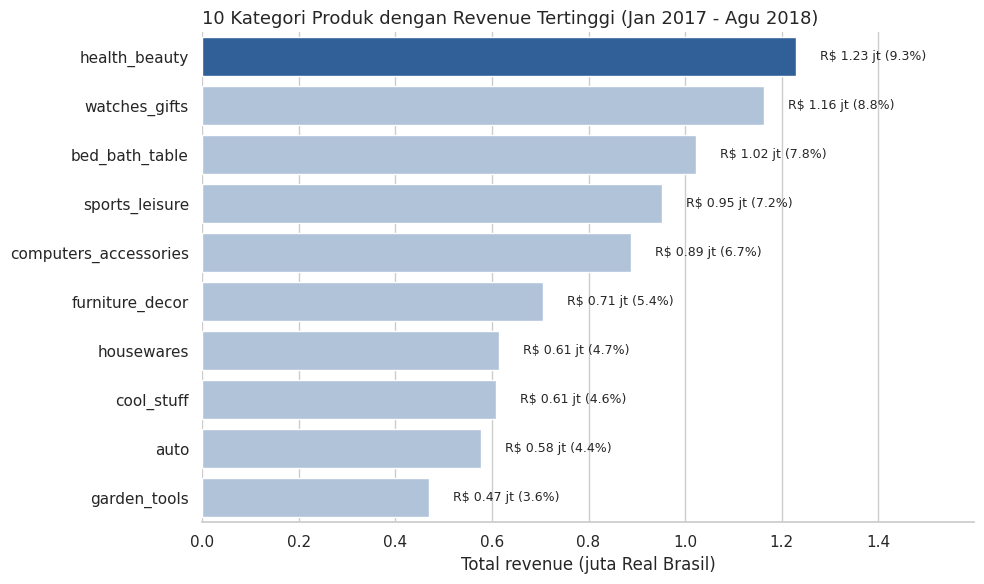

In [40]:
plot_cat = top10_cat.reset_index().copy()
plot_cat["revenue_m"] = plot_cat["revenue"] / 1e6
colors = ["#1f5fa8"] + ["#a9c3e0"] * 9   # sorot kategori teratas

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_cat, x="revenue_m", y="product_category", hue="product_category", palette=colors, legend=False, ax=ax)
for i, row in plot_cat.iterrows():
    ax.text(row["revenue_m"] + 0.05, i, f"R$ {row['revenue_m']:.2f} jt ({row['share_pct']:.1f}%)", va="center", fontsize=9)
ax.set_title("10 Kategori Produk dengan Revenue Tertinggi (Jan 2017 - Agu 2018)", fontsize=13, loc="left")
ax.set_xlabel("Total revenue (juta Real Brasil)")
ax.set_ylabel("")
ax.set_xlim(0, plot_cat["revenue_m"].max() * 1.3)
sns.despine(left=True)
plt.tight_layout()
plt.show()

### 5.2 Pertanyaan 2: Segmentasi pelanggan dengan RFM

Visualisasi ini menjawab Pertanyaan 2.

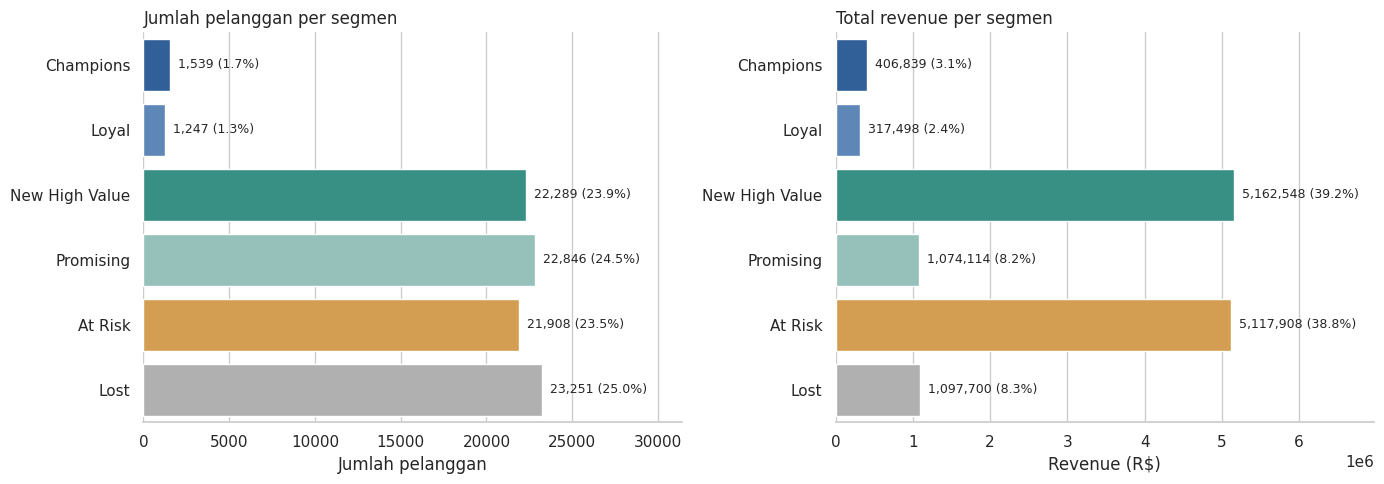

In [41]:
seg_colors = {"Champions": "#1f5fa8", "Loyal": "#4f86c6", "New High Value": "#2a9d8f",
              "Promising": "#8fc7bf", "At Risk": "#e9a23b", "Lost": "#b0b0b0"}
seg_plot = segment_summary.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title, xlabel in [
    (axes[0], "customers", "Jumlah pelanggan per segmen", "Jumlah pelanggan"),
    (axes[1], "revenue", "Total revenue per segmen", "Revenue (R$)"),
]:
    sns.barplot(data=seg_plot, x=col, y="segment", hue="segment", palette=seg_colors, legend=False, order=segment_order, ax=ax)
    pct_col = "customer_pct" if col == "customers" else "revenue_pct"
    for i, seg in enumerate(segment_order):
        val = seg_plot.loc[seg_plot["segment"] == seg, col].iloc[0]
        pct = seg_plot.loc[seg_plot["segment"] == seg, pct_col].iloc[0]
        ax.text(val, i, f"  {val:,.0f} ({pct:.1f}%)", va="center", fontsize=9)
    ax.set_title(title, fontsize=12, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.set_xlim(0, seg_plot[col].max() * 1.35)
sns.despine(left=True)
plt.tight_layout()
plt.show()

### 5.3 Pertanyaan 3: Konsentrasi pelanggan, waktu pengiriman, dan review per state

Bagian 5.3 sampai 5.5 (termasuk peta geospatial) menjawab Pertanyaan 3.

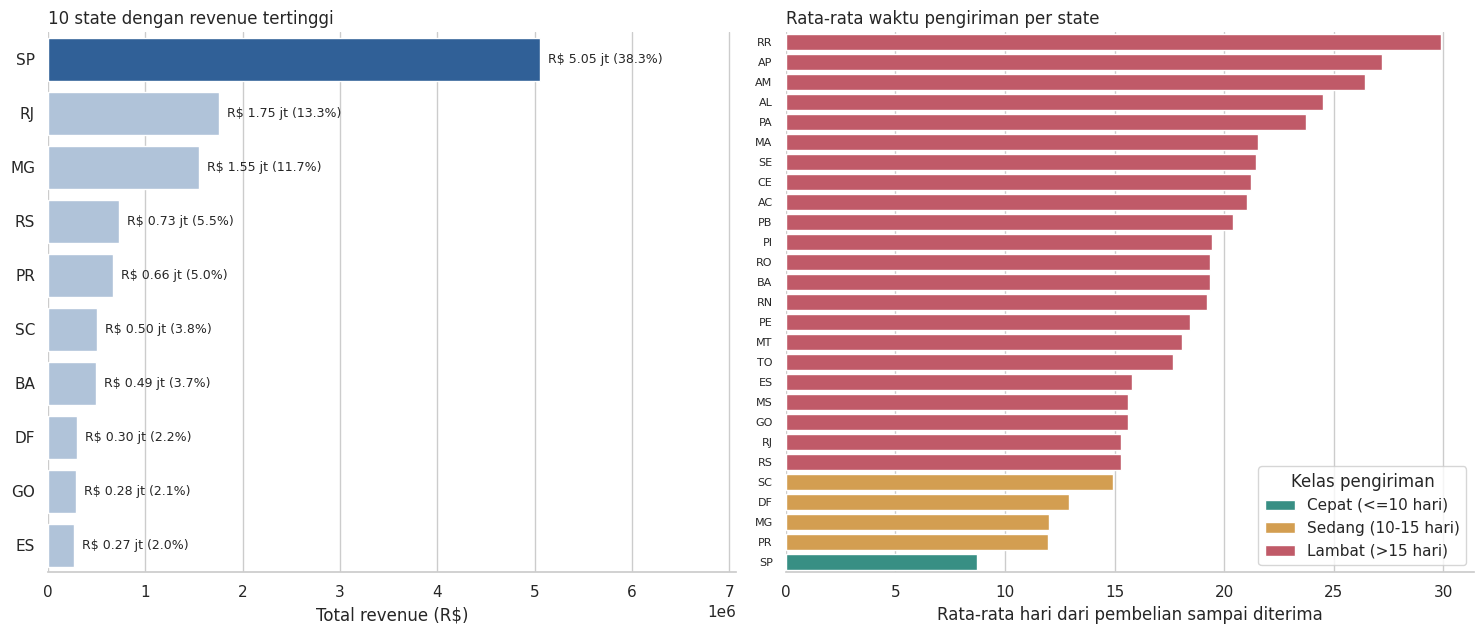

In [42]:
top_states = state_summary.head(10).copy()
class_colors = {"Cepat (<=10 hari)": "#2a9d8f", "Sedang (10-15 hari)": "#e9a23b", "Lambat (>15 hari)": "#d1495b"}
delivery_sorted = state_summary.sort_values("avg_delivery_days", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

sns.barplot(data=top_states, x="revenue", y="customer_state", hue="customer_state",
            palette=["#1f5fa8"] + ["#a9c3e0"] * 9, legend=False, ax=axes[0])
for i, (_, r) in enumerate(top_states.iterrows()):
    axes[0].text(r["revenue"], i, f"  R$ {r['revenue'] / 1e6:.2f} jt ({r['revenue_pct']:.1f}%)", va="center", fontsize=9)
axes[0].set_title("10 state dengan revenue tertinggi", fontsize=12, loc="left")
axes[0].set_xlabel("Total revenue (R$)")
axes[0].set_ylabel("")
axes[0].set_xlim(0, top_states["revenue"].max() * 1.4)

sns.barplot(data=delivery_sorted, x="avg_delivery_days", y="customer_state", hue="delivery_class",
            palette=class_colors, dodge=False, ax=axes[1])
axes[1].set_title("Rata-rata waktu pengiriman per state", fontsize=12, loc="left")
axes[1].set_xlabel("Rata-rata hari dari pembelian sampai diterima")
axes[1].set_ylabel("")
axes[1].legend(title="Kelas pengiriman", loc="lower right")
axes[1].tick_params(axis="y", labelsize=8)
sns.despine(left=True)
plt.tight_layout()
plt.show()

### 5.4 Analisis Geospatial: peta persebaran revenue dan waktu pengiriman

Ukuran lingkaran menunjukkan revenue dan warna menunjukkan rata-rata waktu pengiriman. Koordinat setiap state memakai titik tengah (median) dari data `geolocation` yang sudah dibersihkan.

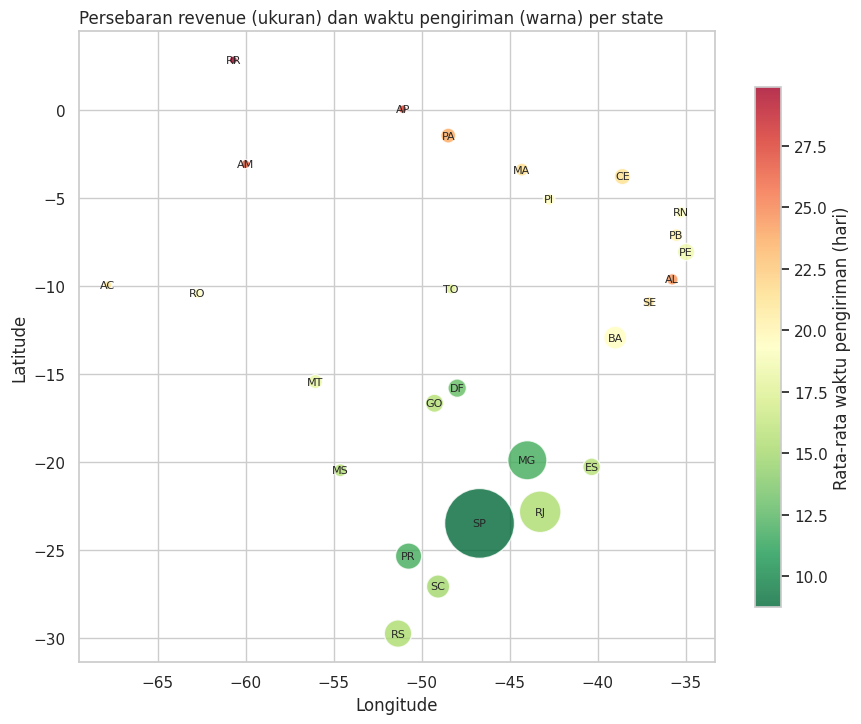

In [43]:
geo_plot = state_summary.dropna(subset=["latitude", "longitude"])

fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(geo_plot["longitude"], geo_plot["latitude"],
                s=geo_plot["revenue"] / geo_plot["revenue"].max() * 2500 + 30,
                c=geo_plot["avg_delivery_days"], cmap="RdYlGn_r", alpha=0.8, edgecolor="white", linewidth=1)
for _, r in geo_plot.iterrows():
    ax.annotate(r["customer_state"], (r["longitude"], r["latitude"]), ha="center", va="center", fontsize=8)
cb = plt.colorbar(sc, ax=ax, shrink=0.7)
cb.set_label("Rata-rata waktu pengiriman (hari)")
ax.set_title("Persebaran revenue (ukuran) dan waktu pengiriman (warna) per state", fontsize=12, loc="left")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [44]:
# Peta interaktif (opsional): membutuhkan folium -> pip install folium
try:
    import folium

    peta = folium.Map(location=[-14.2, -51.9], zoom_start=4, tiles="CartoDB positron")
    max_rev = geo_plot["revenue"].max()
    for _, r in geo_plot.iterrows():
        folium.CircleMarker(
            location=[r["latitude"], r["longitude"]],
            radius=max(5, (r["revenue"] / max_rev) ** 0.5 * 35),
            color="#1f5fa8", fill=True, fill_opacity=0.5,
            popup=folium.Popup(f"<b>{r['customer_state']}</b><br>Revenue: R$ {r['revenue']:,.0f}"
                               f"<br>Pelanggan: {r['customers']:,}<br>Waktu kirim: {r['avg_delivery_days']:.1f} hari"
                               f"<br>Review: {r['avg_review_score']:.2f}", max_width=250),
        ).add_to(peta)
    peta.save("peta_revenue_state.html")
    peta
except ImportError:
    print("folium belum terpasang. Jalankan: pip install folium")

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


### 5.5 Hubungan waktu pengiriman dan kepuasan pelanggan

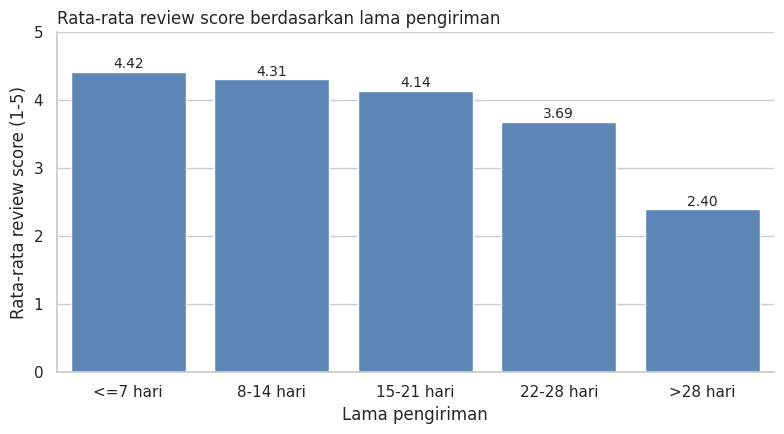

In [45]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=delivery_vs_review.reset_index(), x="delivery_bin", y="avg_review", color="#4f86c6", ax=ax)
for i, v in enumerate(delivery_vs_review["avg_review"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=10)
ax.set_title("Rata-rata review score berdasarkan lama pengiriman", fontsize=12, loc="left")
ax.set_xlabel("Lama pengiriman")
ax.set_ylabel("Rata-rata review score (1-5)")
ax.set_ylim(0, 5)
sns.despine()
plt.tight_layout()
plt.show()

## 6. Conclusion & Recommendation

### Kesimpulan Pertanyaan 1: Kategori produk dengan revenue tertinggi

- Sepuluh kategori teratas menyumbang **62,5%** dari total revenue sebesar R$ 13,18 juta pada Januari 2017 sampai Agustus 2018. Revenue marketplace cukup terkonsentrasi pada sedikit kategori.
- Lima kategori teratas adalah **health_beauty** (R$ 1,23 jt; 9,3%), **watches_gifts** (R$ 1,16 jt; 8,8%), **bed_bath_table** (R$ 1,02 jt; 7,8%), **sports_leisure** (R$ 0,95 jt; 7,2%), dan **computers_accessories** (R$ 0,89 jt; 6,7%).
- Jumlah pesanan tidak selalu sejalan dengan revenue. `bed_bath_table` memiliki pesanan terbanyak (9.264) tetapi hanya peringkat 3 dalam revenue, sedangkan `watches_gifts` hanya 5.488 pesanan namun peringkat 2 karena nilai belanja per pesanan jauh lebih tinggi (sekitar R$ 212 dibanding sekitar R$ 110 pada `bed_bath_table`).

### Kesimpulan Pertanyaan 2: Segmentasi pelanggan (RFM)

- Hanya **3,0%** pelanggan yang membeli lebih dari satu kali. Segmen **Champions** (1.539 pelanggan) dan **Loyal** (1.247 pelanggan) bersama-sama hanya menyumbang sekitar 5,5% revenue.
- Revenue didominasi dua segmen pembeli satu kali bernilai tinggi: **New High Value** (23,9% pelanggan; 39,2% revenue) dan **At Risk** (23,5% pelanggan; 38,8% revenue). Pelanggan At Risk rata-rata belanja R$ 234 dan terakhir membeli sekitar 362 hari sebelum tanggal referensi.
- Segmen **Promising** dan **Lost** (sekitar 49,5% pelanggan) hanya menyumbang sekitar 16,5% revenue karena nilai belanjanya rendah (rata-rata sekitar R$ 47).

### Kesimpulan Pertanyaan 3: Konsentrasi geografis, waktu pengiriman, dan review

- **SP** menyumbang 38,3% revenue (R$ 5,05 jt) dan 41,9% pelanggan. Tiga state teratas (SP, RJ, MG) bersama-sama menyumbang **63,4%** revenue.
- Waktu pengiriman sangat bervariasi. SP rata-rata **8,7 hari**, sedangkan RJ dan RS sekitar **15,3 hari** dan BA **19,3 hari**. State terlambat adalah RR (29,9 hari), AP (27,2), AM (26,4), AL (24,5), dan PA (23,8). Namun state-state ini volumenya kecil (RR hanya 40 pesanan), sehingga rata-ratanya perlu dibaca hati-hati.
- Pengiriman lambat berkaitan dengan kepuasan yang lebih rendah. Review rata-rata turun dari **4,42** (pengiriman 7 hari atau kurang) menjadi **2,40** (lebih dari 28 hari). Sekitar 27% pesanan tiba lebih dari 15 hari. Review RJ (3,97) dan BA (3,93) juga lebih rendah daripada SP (4,25).
- Catatan: hubungan waktu pengiriman dan review ini adalah **korelasi**, bukan bukti sebab-akibat.

### Rekomendasi (Action Item)

1. **Prioritaskan kategori utama.** Fokuskan stok, iklan, dan rekrutmen seller pada lima kategori teratas, terutama `health_beauty` dan `watches_gifts`. Untuk `bed_bath_table` yang volumenya besar tetapi nilai per pesanan rendah, buat paket bundling untuk menaikkan nilai keranjang.
2. **Jalankan program retensi berbasis segmen RFM.**
   - *At Risk* (21.908 pelanggan, sekitar R$ 5,1 jt): kampanye win-back berupa voucher atau email pengingat.
   - *New High Value* (22.289 pelanggan): tawarkan produk pelengkap atau voucher pembelian kedua agar berkembang menjadi Champions.
   - *Champions* dan *Loyal*: program loyalitas sederhana (poin atau gratis ongkir).
3. **Perbaiki logistik di state bernilai tinggi yang lambat.** Utamakan **RJ, RS, dan BA** (revenue besar tetapi pengiriman lebih dari 15 hari) dengan target pengiriman 15 hari atau kurang, misalnya lewat seller atau gudang yang lebih dekat dan evaluasi mitra kurir. Untuk state utara dengan volume kecil, cukup tampilkan estimasi pengiriman yang jujur agar ekspektasi pelanggan terkelola.